# 02 - Unicode attack generation

Generate a shared attacked-test corpus so every classifier sees the same perturbations.

**Inputs:** Processed test rows from notebook 01 and attack settings from `config/experiment.yaml`.  
**Outputs:** `attacks.parquet`, `attack_coverage.csv`, and a nominal-versus-effective-strength plot.


## Setup and attack definitions

Each example uses a random seed derived from the attack seed, example ID, family and strength, so generation does not depend on row order.


In [22]:
import hashlib
import json
import random
import unicodedata
from pathlib import Path
import pandas as pd
import yaml

# Same path setup, repeated for independent execution.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CONFIG = yaml.safe_load((ROOT / 'config/experiment.yaml').read_text(encoding='utf-8'))

PATHS = {key: ROOT / value for key, value in CONFIG['paths'].items()}
for directory in (PATHS['attacks'].parent, PATHS['tables'], PATHS['figures'],):
    directory.mkdir(parents=True, exist_ok=True)

def stable_int(*parts, modulo=2**32 - 1):
    digest = hashlib.sha256('||'.join(map(str, parts)).encode('utf-8')).hexdigest()
    return int(digest[:16], 16) % modulo
    
#great deal  of those  homoglyphs are greek or cyrillic letters
HOMOGLYPH_MAP = { 
    'A': ('Α', 'А'), 'B': ('Β', 'В'), 'C': ('Ϲ', 'С'), 'E': ('Ε', 'Е'),
    'H': ('Η', 'Н'), 'I': ('Ι', 'І'), 'J': ('Ј',), 'K': ('Κ', 'К'),
    'M': ('Μ', 'М'), 'N': ('Ν',), 'O': ('Ο', 'О'), 'P': ('Ρ', 'Р'),
    'S': ('Ѕ',), 'T': ('Τ', 'Т'), 'X': ('Χ', 'Х'), 'Y': ('Υ', 'У'), 'Z': ('Ζ',),
    'a': ('а',), 'c': ('с',), 'e': ('е',), 'h': ('һ',), 'i': ('і',),
    'j': ('ј',), 'k': ('κ',), 'o': ('ο', 'о'), 'p': ('р',), 's': ('ѕ',),
    'x': ('х',), 'y': ('у',),
}

INVISIBLE_CHARS = tuple(chr(int(cp, 16)) for cp in CONFIG['attacks']['invisible_codepoints'])

# Return a fullwidth Unicode compatibility variant of an ASCII character.
def compatibility_candidate(ch):
    code = ord(ch)
    if 0x21 <= code <= 0x7E:
        candidate = chr(code + 0xFEE0)
        if unicodedata.normalize('NFKC', candidate) == ch:
            return candidate
    return None


# Return a canonically equivalent decomposed Unicode representation, if available.
def composition_candidate(ch):
    decomposed = unicodedata.normalize('NFD', ch)
    if decomposed != ch and unicodedata.normalize('NFC', decomposed) == unicodedata.normalize('NFC', ch):
        return decomposed
    return None


# Describe each character using its Unicode code point and official name.
def codepoint_description(text):
    return [
        {'char': ch, 'codepoint': f'U+{ord(ch):04X}', 'name': unicodedata.name(ch, 'UNNAMED')}
        for ch in text
    ]


#Generate all valid adversarial replacements for a character and attack family.
def options_for_position(ch, family):
    options = []
    if family in {'homoglyph', 'mixed'} and ch in HOMOGLYPH_MAP:
        options.extend(('homoglyph', candidate) for candidate in HOMOGLYPH_MAP[ch])
    if family in {'invisible', 'mixed'} and ch.isalnum():
        options.extend(('invisible', ch + candidate) for candidate in INVISIBLE_CHARS)
    if family in {'compatibility', 'mixed'}:
        candidate = compatibility_candidate(ch)
        if candidate is not None:
            options.append(('compatibility', candidate))
    if family in {'composition', 'mixed'}:
        candidate = composition_candidate(ch)
        if candidate is not None:
            options.append(('composition', candidate))
    return options


# Apply reproducible Unicode adversarial perturbations at the requested strength.
def attack_text(text, family, strength, seed, example_id):
    if family not in CONFIG['attacks']['families']:
        raise ValueError(f'Unknown attack family: {family}')
    #remember options for position returns a list of options for a family attack for for a character
    options = {idx: options_for_position(ch, family) for idx, ch in enumerate(text)}
    options = {idx: values for idx, values in options.items() if values}
    #just get a list of usable character idx for the attack
    eligible = sorted(options)
    if not eligible or strength <= 0:
        return {'attacked_text': text, 'eligible_count': len(eligible), 'changed_count': 0, 'effective_strength': 0.0, 'modification_log': '[]'}
    #bounded number of character to modify, around percentage of strenght of attack
    budget = min(len(eligible), max(1, int(round(strength * len(eligible)))))
    rng = random.Random(stable_int(seed, example_id, family, f'{strength:.4f}'))
    selected = sorted(rng.sample(eligible, budget))
    replacements = {}
    log = []
    for idx in selected:
        applied_family, replacement = rng.choice(options[idx]) #like [('homoglyph', 'ј')]
        replacements[idx] = (applied_family, replacement)
        log.append({
            'index': idx, 'family': applied_family,
            'source': codepoint_description(text[idx]),
            'replacement': codepoint_description(replacement),
        })
    # Is this position in replacements? yes use repl no use original
    attacked = ''.join(replacements[idx][1] if idx in replacements else ch for idx, ch in enumerate(text))
    return {
        'attacked_text': attacked,
        'eligible_count': len(eligible),
        'changed_count': len(selected),
        'effective_strength': len(selected) / len(eligible),
        'modification_log': json.dumps(log, ensure_ascii=True, separators=(',', ':')),
    }


# Render invisible Unicode characters explicitly for easier inspection and debugging.
def visible_unicode(text):
    return ''.join(ch if ch.isprintable() and ch not in INVISIBLE_CHARS else f'\\u{ord(ch):04X}' for ch in text)

In [20]:
options = {
    idx: options_for_position(ch, "homoglyph")
    for idx, ch in enumerate("jonh")
}
options = {idx: values for idx, values in options.items() if values}
options


{0: [('homoglyph', 'ј')],
 1: [('homoglyph', 'ο'), ('homoglyph', 'о')],
 3: [('homoglyph', 'һ')]}

## Generate the attack conditions

Apply the configured families, strengths and seeds to each test example. Strength controls the fraction of eligible positions selected, with at least one change when a position is eligible. Store the clean and attacked text together with their labels and edits.


In [24]:
data = pd.read_parquet(PATHS['processed_data'])
data

,dataset,split,example_id,original_index,text,label,label_name
0,banking77,train,banking77:train:7059,7059,Why can't I transfer money to a beneficiary,54,beneficiary_not_allowed
1,banking77,train,banking77:train:7881,7881,"If I want to send out more cards, do you charg...",60,getting_spare_card
2,banking77,train,banking77:train:82,82,How can I track my card's delivery?,0,card_arrival
3,banking77,train,banking77:train:7194,7194,Why was I charged an extra fee when doing a tr...,55,transfer_fee_charged
4,banking77,train,banking77:train:4818,4818,What should I do if I don't know my password?,38,passcode_forgotten
...,...,...,...,...,...,...,...
19020,trec,test,trec:test:495,495,Who was the 22nd President of the US ?,3,HUM
19021,trec,test,trec:test:496,496,What is the money they use in Zambia ?,1,ENTY
19022,trec,test,trec:test:497,497,How many feet in a mile ?,5,NUM
19023,trec,test,trec:test:498,498,What is the birthstone of October ?,1,ENTY


In [25]:
data = pd.read_parquet(PATHS['processed_data'])
test = data[data['split'] == 'test'].copy()
records = []
#index false to expose rows differently, for some reason
for row in test.itertuples(index=False):
    for family in CONFIG['attacks']['families']:
        for strength in CONFIG['attacks']['strengths']:
            for attack_seed in CONFIG['attacks']['seeds']:
                result = attack_text(row.text, family, float(strength), int(attack_seed), row.example_id)
                records.append({
                    'dataset': row.dataset, 'example_id': row.example_id, 'label': int(row.label),
                    'label_name': row.label_name, 'clean_text': row.text, 'attacked_text': result['attacked_text'],
                    'attack': family, 'strength': float(strength), 'attack_seed': int(attack_seed),
                    'eligible_count': result['eligible_count'], 'changed_count': result['changed_count'],
                    'effective_strength': result['effective_strength'], 'modification_log': result['modification_log'],
                })


In [26]:
records

[{'dataset': 'banking77',
  'example_id': 'banking77:test:0',
  'label': 0,
  'label_name': 'card_arrival',
  'clean_text': 'How do I locate my card?',
  'attacked_text': 'How do I loсate my card?',
  'attack': 'homoglyph',
  'strength': 0.05,
  'attack_seed': 13,
  'eligible_count': 11,
  'changed_count': 1,
  'effective_strength': 0.09090909090909091,
  'modification_log': '[{"index":11,"family":"homoglyph","source":[{"char":"c","codepoint":"U+0063","name":"LATIN SMALL LETTER C"}],"replacement":[{"char":"\\u0441","codepoint":"U+0441","name":"CYRILLIC SMALL LETTER ES"}]}]'},
 {'dataset': 'banking77',
  'example_id': 'banking77:test:0',
  'label': 0,
  'label_name': 'card_arrival',
  'clean_text': 'How do I locate my card?',
  'attacked_text': 'How do I loсate my card?',
  'attack': 'homoglyph',
  'strength': 0.05,
  'attack_seed': 37,
  'eligible_count': 11,
  'changed_count': 1,
  'effective_strength': 0.09090909090909091,
  'modification_log': '[{"index":11,"family":"homoglyph","sou

## Attack coverage

Coverage is the fraction of rows whose text changed. `eligible_examples` counts examples that can be changed, `mean_changes` is the average number of edits, and `mean_effective_strength` is the fraction of eligible positions edited.


In [29]:
attacks = pd.DataFrame.from_records(records)
attacks.to_parquet(PATHS['attacks'], index=False)

coverage = attacks.groupby(['dataset', 'attack', 'strength']).agg(
    examples=('example_id', 'nunique'), eligible_examples=('eligible_count', lambda values: int((values > 0).sum() / len(CONFIG['attacks']['seeds']))),
    coverage=('changed_count', lambda values: float((values > 0).mean())), mean_changes=('changed_count', 'mean'),
    mean_effective_strength=('effective_strength', 'mean'),
).reset_index()
coverage.to_csv(PATHS['tables'] / 'attack_coverage.csv', index=False)


In [30]:
coverage

,dataset,attack,strength,examples,eligible_examples,coverage,mean_changes,mean_effective_strength
0,banking77,compatibility,0.05,3080,3080,1.0,2.222727,0.050191
1,banking77,compatibility,0.10,3080,3080,1.0,4.422727,0.099936
2,banking77,compatibility,0.20,3080,3080,1.0,8.850649,0.200154
3,banking77,compatibility,0.40,3080,3080,1.0,17.689935,0.399971
4,banking77,compatibility,0.75,3080,3080,1.0,33.165260,0.749853
5,banking77,composition,0.05,3080,0,0.0,0.000000,0.000000
6,banking77,composition,0.10,3080,0,0.0,0.000000,0.000000
7,banking77,composition,0.20,3080,0,0.0,0.000000,0.000000
8,banking77,composition,0.40,3080,0,0.0,0.000000,0.000000
9,banking77,composition,0.75,3080,0,0.0,0.000000,0.000000


## Nominal and effective strength

Compare the requested strength with the fraction of eligible positions actually changed.


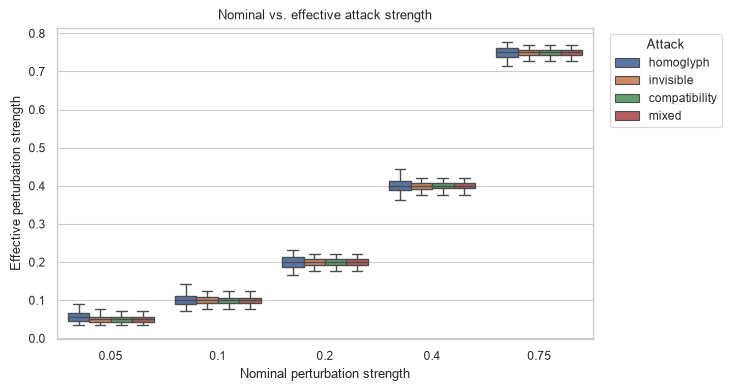

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='paper')

# Keep examples with at least one position that can be attacked.
plot_data = attacks[attacks['eligible_count'] > 0].copy()

fig, ax = plt.subplots(figsize=(7.2, 3.8), constrained_layout=True)

sns.boxplot(
    data=plot_data,
    x='strength',
    y='effective_strength',
    hue='attack',
    showfliers=False,
    ax=ax
)

ax.set(
    xlabel='Nominal perturbation strength',
    ylabel='Effective perturbation strength',
    title='Nominal vs. effective attack strength'
)

ax.legend(title='Attack', bbox_to_anchor=(1.02, 1), loc='upper left')

fig.savefig(
    PATHS['figures'] / 'attack_effective_strength.pdf',
    bbox_inches='tight'
)

plt.show()


## Interpretation

Composition changes no inputs in these test sets, so its unchanged scores do not demonstrate robustness to this attack.
